# NYC Taxi Times

**Author:** Clarice Mottet  

---

## Objective

Build a model to predict the total ride duration for NYC taxis

---

## Dataset
**Source:**
- kaggle


## Table of Contents

- [1. Load Data](#1-load-data)
- [2. Data Overview](#2-data-overview)
- [3. Data Cleaning](#3-data-cleaning)
- [4. Feature Engineering](#4-feature-enginerring)
- [5. Exploratory Data Analysis](#5-exploratory-data-analysis)
- [6. Correlation Analysis](#6-correlation-analysis)
- [7. Modeling](#7-modeling)
- [8. Model Evaluation](#8-model-evaluation)


## Notes

- Random seed = 42
- Train/Test split = pre-determined by datasets given
- Evaluation metric = Root Mean Squared Log Error

# 1. Load Data

In [22]:
#libraries

import pandas as pd
import numpy as np
import os
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt

project_root = Path.cwd().parent          # if notebook is inside notebooks/


* Import in train and test datasets

In [23]:
#import in the datasets

#establish filepath
raw_path = project_root / "data" / "raw"
os.listdir(raw_path)

df_test = pd.read_csv(raw_path / "test.csv", dtype = str)
df_train = pd.read_csv(raw_path / "train.csv", dtype = str)
df_sample = pd.read_csv(raw_path / "sample_submission.csv", dtype = str)

# 2. Data Overview

- number of rows
- number of columns
- same columns in both datasets

In [24]:
#number of rows
print(f"df_train rows: {len(df_train)}")
print(f"df_test rows: {len(df_test)}")

list_test_col = list(df_test.columns)
list_train_col = list(df_train.columns)

list_all_col = list_test_col + list_train_col
list_all_col = list(set(list_all_col))
print(f"all columns: {list_all_col}")

list_test_doesnt = [x for x in list_all_col if x not in list_test_col]
print(f"columns not included in test: {list_test_doesnt}")

list_train_doesnt = [x for x in list_all_col if x not in list_train_col]
print(f"columns not included in train: {list_train_doesnt}")


df_train rows: 1458644
df_test rows: 625134
all columns: ['trip_duration', 'dropoff_latitude', 'vendor_id', 'dropoff_longitude', 'id', 'pickup_datetime', 'pickup_longitude', 'dropoff_datetime', 'passenger_count', 'store_and_fwd_flag', 'pickup_latitude']
columns not included in test: ['trip_duration', 'dropoff_datetime']
columns not included in train: []


# 3. Data Cleaning

* dtype
* nulls
* duplicates

In [25]:
#dtype

for col in df_train.columns:
    df_train[col] = df_train[col].str.strip()

#numeric columns
list_col_num = ['vendor_id', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
                'trip_duration']
list_col_date = ['pickup_datetime', 'dropoff_datetime']

#convert to numberic

list_convert_num = [x for x in list_col_num if x in df_train.columns]
df_train[list_convert_num] = df_train[list_convert_num].apply(pd.to_numeric)

list_convert_num = [x for x in list_col_num if x in df_test.columns]
df_test[list_convert_num] = df_test[list_convert_num].apply(pd.to_numeric)

#convert to datetime

list_convert_date = [x for x in list_col_date if x in df_train.columns]
df_train[list_convert_date] = df_train[list_convert_date].apply(pd.to_datetime)

list_convert_date = [x for x in list_col_date if x in df_test.columns]
df_test[list_convert_date] = df_test[list_convert_date].apply(pd.to_datetime)


In [26]:
#nulls

print("null counts:")
print(df_train.isnull().sum())

print("\nunique value counts:")
print(df_train.nunique())

null counts:
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

unique value counts:
id                    1458644
vendor_id                   2
pickup_datetime       1380222
dropoff_datetime      1380377
passenger_count            10
pickup_longitude        23047
pickup_latitude         45245
dropoff_longitude       33821
dropoff_latitude        62519
store_and_fwd_flag          2
trip_duration            7417
dtype: int64


In [27]:
#duplicates

#duplicates by id
dup_id_count = df_train.duplicated(subset='id').sum()
print(f"duplicate rows by 'id': {dup_id_count}")

#duplicates by all columns except id
cols_no_id = [col for col in df_train.columns if col != 'id']
dup_no_id_count = df_train.duplicated(subset=cols_no_id).sum()
print(f"duplicate rows by all columns except 'id': {dup_no_id_count}")


duplicate rows by 'id': 0
duplicate rows by all columns except 'id': 7


In [28]:
#explored data in another notebook and found the below needs to be cleaned

def clean_data(df_):
    """
    - removes instances where passenger count is 60
    - removes instances where trip duration is less than 1 min or more than 4 hours
    - remove instances where the pickup and dropoff location is the same but the trip_duration is more than 15 minutes
    - remove instances where the longitude and latitude are outside of NYC and the suburb area
    """

    #removes instances where passenger count is 0
    mask_passenger_count = (df_['passenger_count']>0)

    #removes instances where the trip duration is less than a min, more than 4 hours
    MIN_DURATION = 60
    MAX_DURATION = 14400
    mask_duration = (df_['trip_duration'].between(MIN_DURATION, MAX_DURATION))

    #removes instances where pickup/dropoff is the same and the trip is more than 15 min
    mask_same_loc = (
            (df_['pickup_longitude']==df_['dropoff_longitude']) &
            (df_['pickup_latitude']==df_['dropoff_latitude']) &
            (df_['trip_duration']>900)
            )

    #removes instances where the trip is outside NYC
    MIN_LONGITUDE = -74.30
    MAX_LONGITUDE = -73.60

    MIN_LATITUDE = 40.45
    MAX_LATITUDE = 41.00

    mask_range = (
        df_['pickup_longitude'].between(MIN_LONGITUDE, MAX_LONGITUDE) &
        df_['dropoff_longitude'].between(MIN_LONGITUDE, MAX_LONGITUDE) &
        df_['pickup_latitude'].between(MIN_LATITUDE, MAX_LATITUDE) &
        df_['dropoff_latitude'].between(MIN_LATITUDE, MAX_LATITUDE)
        )

    df_ = df_[mask_passenger_count & mask_duration & mask_range].copy()
    df_ = df_[~mask_same_loc].copy()
    df_.reset_index(drop = True, inplace = True)

    return df_


In [29]:
print(f"records before cleaning: {len(df_train)}")
df_train = clean_data(df_train)
print(f"records after cleaning: {len(df_train)}")


records before cleaning: 1458644
records after cleaning: 1446403


/var/folders/jp/kjpvm0x51cb5ykf73t5nzkqr0000gn/T/ipykernel_36617/2809711754.py:41: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_ = df_[~mask_same_loc].copy()


# 4. Feature Engineering

- haversine distance + log
- manhattan distance + log
- cyclical hour, weekday, month variables
- is weekend: indicator 0 if weekday, 1 if weekend
- bearing: direction where the trip was going from pickup to dropoff


In [30]:
#haversine and manhattan distance

df_train["log_trip_duration"] = np.log1p(df_train["trip_duration"])

# Earth's radius in kilometers
R = 6371

def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate the Haversine distance between two points (in km).
    """
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


In [31]:
# Haversine distance
df_train["haversine_distance"] = haversine_distance(
    df_train["pickup_latitude"],
    df_train["pickup_longitude"],
    df_train["dropoff_latitude"],
    df_train["dropoff_longitude"]
)

# Manhattan distance (north-south + east-west)
lat_distance = haversine_distance(
    df_train["pickup_latitude"],
    df_train["pickup_longitude"],
    df_train["dropoff_latitude"],
    df_train["pickup_longitude"]
)

lon_distance = haversine_distance(
    df_train["pickup_latitude"],
    df_train["pickup_longitude"],
    df_train["pickup_latitude"],
    df_train["dropoff_longitude"]
)

df_train["manhattan_distance"] = lat_distance + lon_distance

df_train['log_haversine_distance'] = np.log1p(df_train["haversine_distance"])
df_train['log_manhattan_distance'] = np.log1p(df_train["manhattan_distance"])

df_train[["haversine_distance", "manhattan_distance"]].describe()

,haversine_distance,manhattan_distance
count,1.446403e+06,1.446403e+06
mean,3.446929e+00,4.455209e+00
std,3.893044e+00,5.179339e+00
min,0.000000e+00,0.000000e+00
25%,1.245971e+00,1.589083e+00
50%,2.107376e+00,2.706150e+00
75%,3.892262e+00,5.020845e+00
max,4.776513e+01,6.761568e+01


In [32]:
# Haversine distance
df_test["haversine_distance"] = haversine_distance(
    df_test["pickup_latitude"],
    df_test["pickup_longitude"],
    df_test["dropoff_latitude"],
    df_test["dropoff_longitude"]
)

# Manhattan distance (north-south + east-west)
lat_distance = haversine_distance(
    df_test["pickup_latitude"],
    df_test["pickup_longitude"],
    df_test["dropoff_latitude"],
    df_test["pickup_longitude"]
)

lon_distance = haversine_distance(
    df_test["pickup_latitude"],
    df_test["pickup_longitude"],
    df_test["pickup_latitude"],
    df_test["dropoff_longitude"]
)

df_test["manhattan_distance"] = lat_distance + lon_distance

df_test['log_haversine_distance'] = np.log1p(df_test["haversine_distance"])
df_test['log_manhattan_distance'] = np.log1p(df_test["manhattan_distance"])

In [33]:
#create hour, weekday and month cyclical variables

def convert_hour(df_, col_):
    df_["hour_"+col_] = df_[col_].dt.hour
    df_["hour_sin_"+col_] = np.sin(2 * np.pi * df_["hour_"+col_] / 24)
    df_["hour_cos_"+col_] = np.cos(2 * np.pi * df_["hour_"+col_] / 24)
    return df_

def convert_day_of_week(df_, col_):
    df_["dow_"+col_] = df_[col_].dt.dayofweek
    df_["dow_sin_"+col_] = np.sin(2*np.pi*df_["dow_"+col_]/7)
    df_["dow_cos_"+col_] = np.cos(2*np.pi*df_["dow_"+col_]/7)
    return df_

def convert_month(df_, col_):
    df_["month_"+col_] = df_[col_].dt.month
    df_["month_sin_"+col_] = np.sin(2*np.pi*df_["month_"+col_]/12)
    df_["month_cos_"+col_] = np.cos(2*np.pi*df_["month_"+col_]/12)
    return df_


In [34]:
df_train = convert_hour(df_train, "pickup_datetime")
df_train = convert_day_of_week(df_train, "pickup_datetime")
df_train = convert_month(df_train, "pickup_datetime")

df_test = convert_hour(df_test, "pickup_datetime")
df_test = convert_day_of_week(df_test, "pickup_datetime")
df_test = convert_month(df_test, "pickup_datetime")

In [35]:
#is weekend

df_train["is_weekend"] = df_train["dow_pickup_datetime"].isin([5, 6]).astype(int)
df_test["is_weekend"] = df_test["dow_pickup_datetime"].isin([5, 6]).astype(int)

In [ ]:
#bearing 


def calculate_bearing(lat1, lon1, lat2, lon2):
    """
    Calculate the initial compass bearing (in degrees, 0-360) from point 1 to point 2.
    """
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlon = lon2 - lon1

    x = np.sin(dlon) * np.cos(lat2)
    y = (
        np.cos(lat1) * np.sin(lat2)
        - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    )

    bearing = np.degrees(np.arctan2(x, y))

    return (bearing + 360) % 360

df_train["bearing"] = calculate_bearing(
    df_train["pickup_latitude"],
    df_train["pickup_longitude"],
    df_train["dropoff_latitude"],
    df_train["dropoff_longitude"]
)

df_test["bearing"] = calculate_bearing(
    df_test["pickup_latitude"],
    df_test["pickup_longitude"],
    df_test["dropoff_latitude"],
    df_test["dropoff_longitude"]
)

df_train["bearing_sin"] = np.sin(
    2 * np.pi * df_train["bearing"] / 360
)
df_train["bearing_cos"] = np.cos(
    2 * np.pi * df_train["bearing"] / 360
)

df_test["bearing_sin"] = np.sin(
    2 * np.pi * df_test["bearing"] / 360
)
df_test["bearing_cos"] = np.cos(
    2 * np.pi * df_test["bearing"] / 360
)

In [50]:
#one hot encoding

df_train['store_and_fwd_flag_ind'] = 0
df_train.loc[df_train['store_and_fwd_flag']=='Y', 'store_and_fwd_flag_ind'] = 1

df_test['store_and_fwd_flag_ind'] = 0
df_test.loc[df_test['store_and_fwd_flag']=='Y', 'store_and_fwd_flag_ind'] = 1


df_train['vendor_id_1'] = 0
df_train.loc[df_train['vendor_id']==1, 'vendor_id_1'] = 1
df_train['vendor_id_2'] = 0
df_train.loc[df_train['vendor_id']==2, 'vendor_id_2'] = 1

df_test['vendor_id_1'] = 0
df_test.loc[df_test['vendor_id']==1, 'vendor_id_1'] = 1
df_test['vendor_id_2'] = 0
df_test.loc[df_test['vendor_id']==2, 'vendor_id_2'] = 1


# 5. Exploratory Data Analysis

- Review Trip Duration (target will be log trip duration, trip duration is heavily skewed)
- Reviewed hour of day and day of week by trip duration, varies slightly
- distribution of passenger count varies greatly, there is mostly only 1 passenger
- scatter plot of distance and trip duration doesn't reveal anything out of the normal

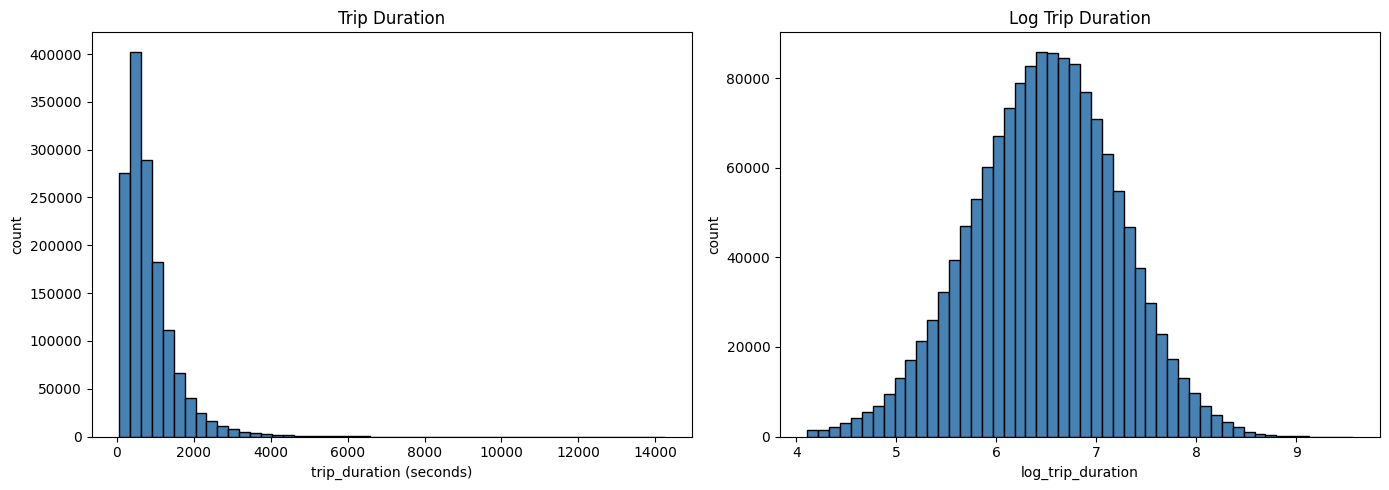

In [37]:
#trip duration histogram

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_train["trip_duration"], bins=50, color="steelblue", edgecolor="black")
axes[0].set_title("Trip Duration")
axes[0].set_xlabel("trip_duration (seconds)")
axes[0].set_ylabel("count")

axes[1].hist(df_train["log_trip_duration"], bins=50, color="steelblue", edgecolor="black")
axes[1].set_title("Log Trip Duration")
axes[1].set_xlabel("log_trip_duration")
axes[1].set_ylabel("count")

plt.tight_layout()
plt.show()

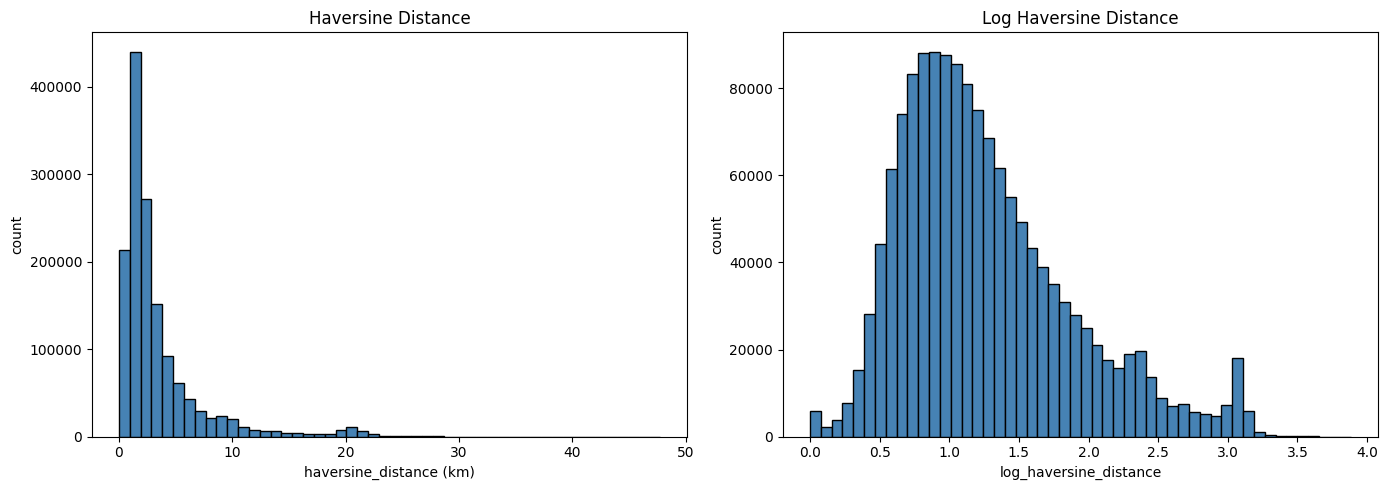

In [38]:
#histogram haversine distance

#haversine distance histogram

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_train["haversine_distance"], bins=50, color="steelblue", edgecolor="black")
axes[0].set_title("Haversine Distance")
axes[0].set_xlabel("haversine_distance (km)")
axes[0].set_ylabel("count")

axes[1].hist(df_train["log_haversine_distance"], bins=50, color="steelblue", edgecolor="black")
axes[1].set_title("Log Haversine Distance")
axes[1].set_xlabel("log_haversine_distance")
axes[1].set_ylabel("count")

plt.tight_layout()
plt.show()


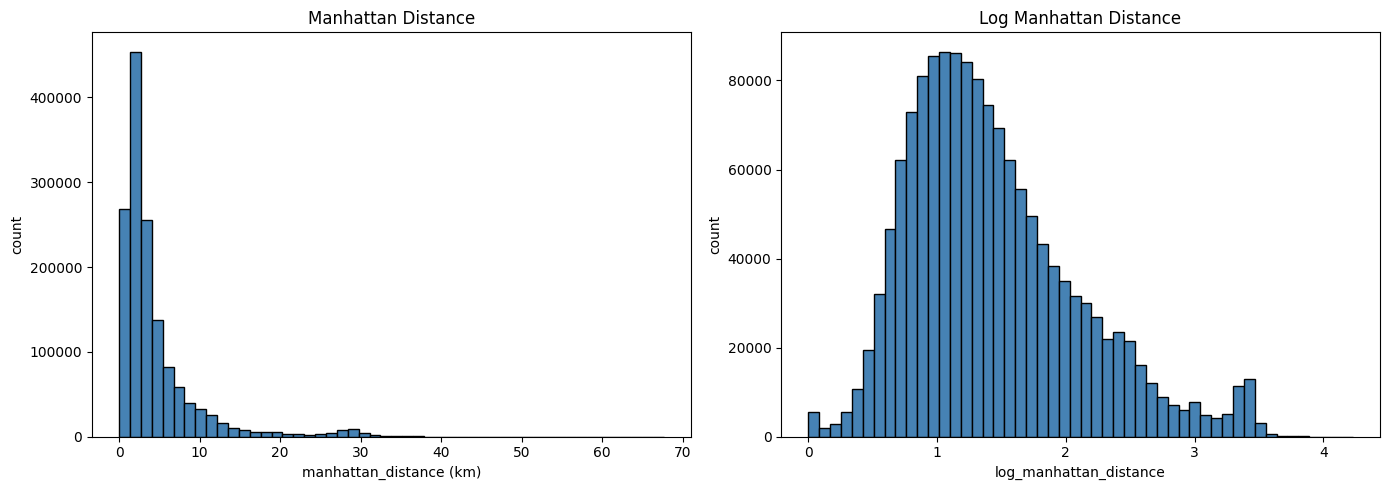

In [39]:
#manhattan distance histogram

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_train["manhattan_distance"], bins=50, color="steelblue", edgecolor="black")
axes[0].set_title("Manhattan Distance")
axes[0].set_xlabel("manhattan_distance (km)")
axes[0].set_ylabel("count")

axes[1].hist(df_train["log_manhattan_distance"], bins=50, color="steelblue", edgecolor="black")
axes[1].set_title("Log Manhattan Distance")
axes[1].set_xlabel("log_manhattan_distance")
axes[1].set_ylabel("count")

plt.tight_layout()
plt.show()


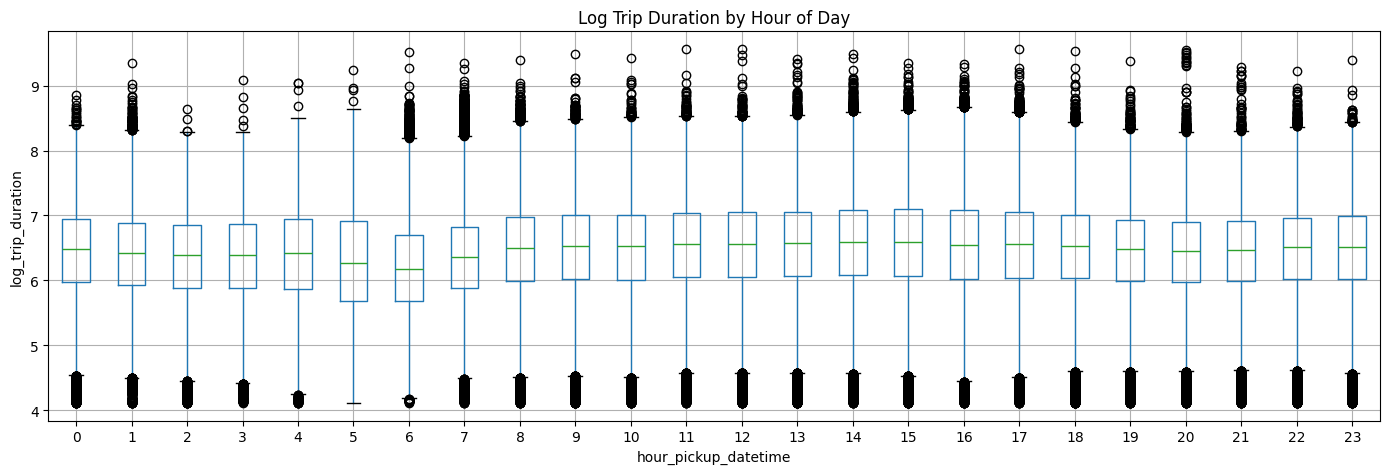

In [40]:
#box plot of log trip duration by hour of day

fig, ax = plt.subplots(figsize=(14, 5))

df_train.boxplot(column="log_trip_duration", by="hour_pickup_datetime", ax=ax)

ax.set_title("Log Trip Duration by Hour of Day")
plt.suptitle("")
ax.set_xlabel("hour_pickup_datetime")
ax.set_ylabel("log_trip_duration")

plt.tight_layout()
plt.show()


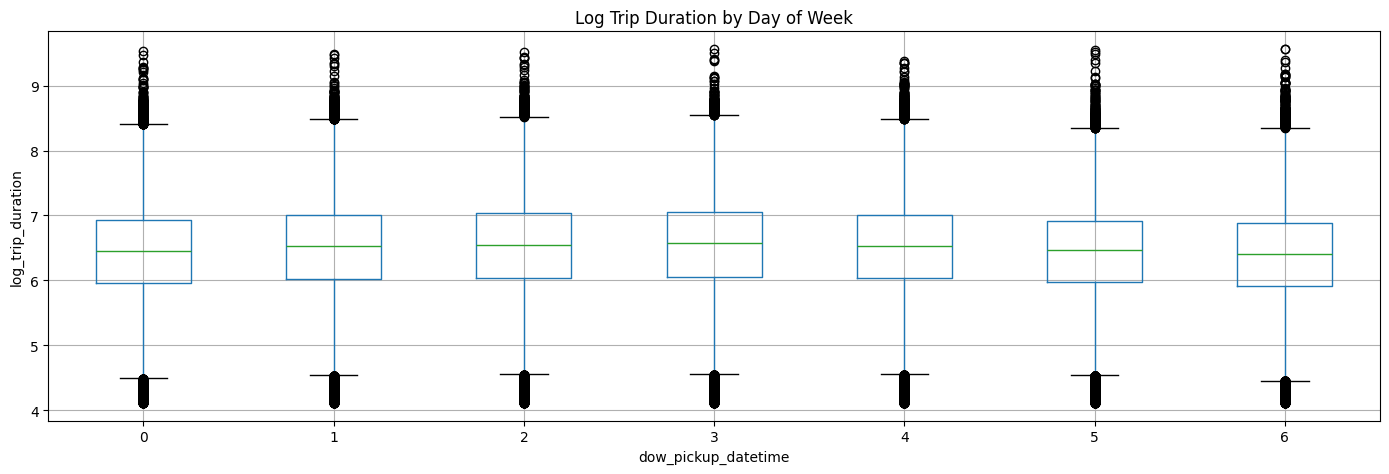

In [41]:
#box plot of log trip duration by day of week

fig, ax = plt.subplots(figsize=(14, 5))

df_train.boxplot(column="log_trip_duration", by="dow_pickup_datetime", ax=ax)

ax.set_title("Log Trip Duration by Day of Week")
plt.suptitle("")
ax.set_xlabel("dow_pickup_datetime")
ax.set_ylabel("log_trip_duration")

plt.tight_layout()
plt.show()


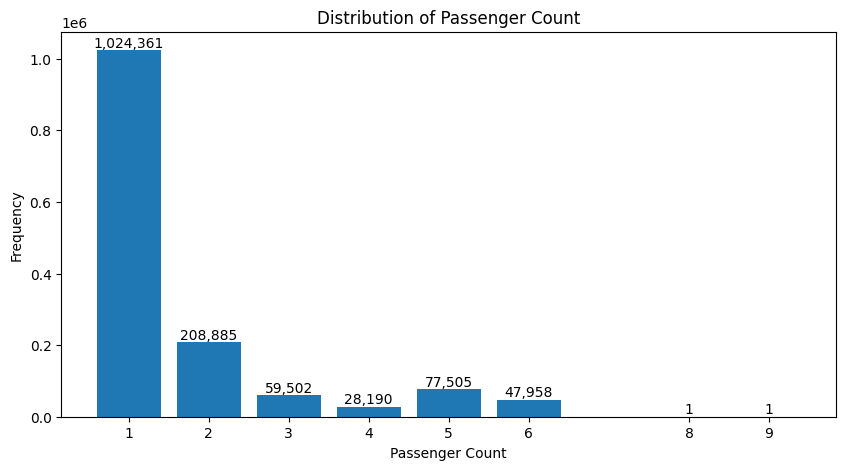

In [42]:
#passenger count

import matplotlib.pyplot as plt

passenger_counts = (
    df_train["passenger_count"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    passenger_counts.index,
    passenger_counts.values
)

# Add frequency labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.xlabel("Passenger Count")
plt.ylabel("Frequency")
plt.title("Distribution of Passenger Count")

plt.xticks(passenger_counts.index)

plt.show()

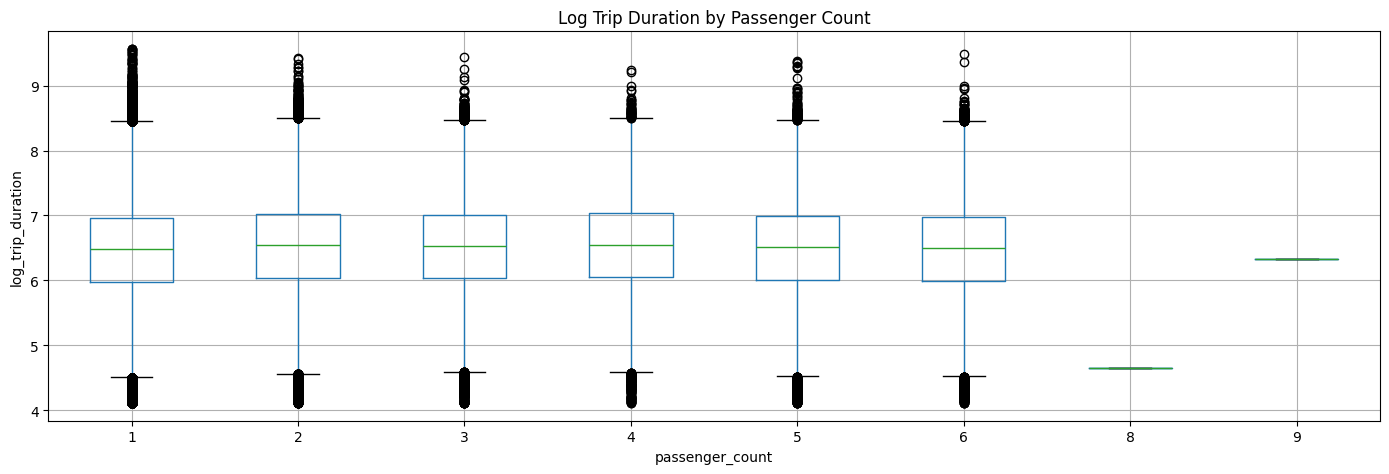

In [43]:
#box plot of log trip duration by passenger count

fig, ax = plt.subplots(figsize=(14, 5))

df_train.boxplot(column="log_trip_duration", by="passenger_count", ax=ax)

ax.set_title("Log Trip Duration by Passenger Count")
plt.suptitle("")
ax.set_xlabel("passenger_count")
ax.set_ylabel("log_trip_duration")

plt.tight_layout()
plt.show()


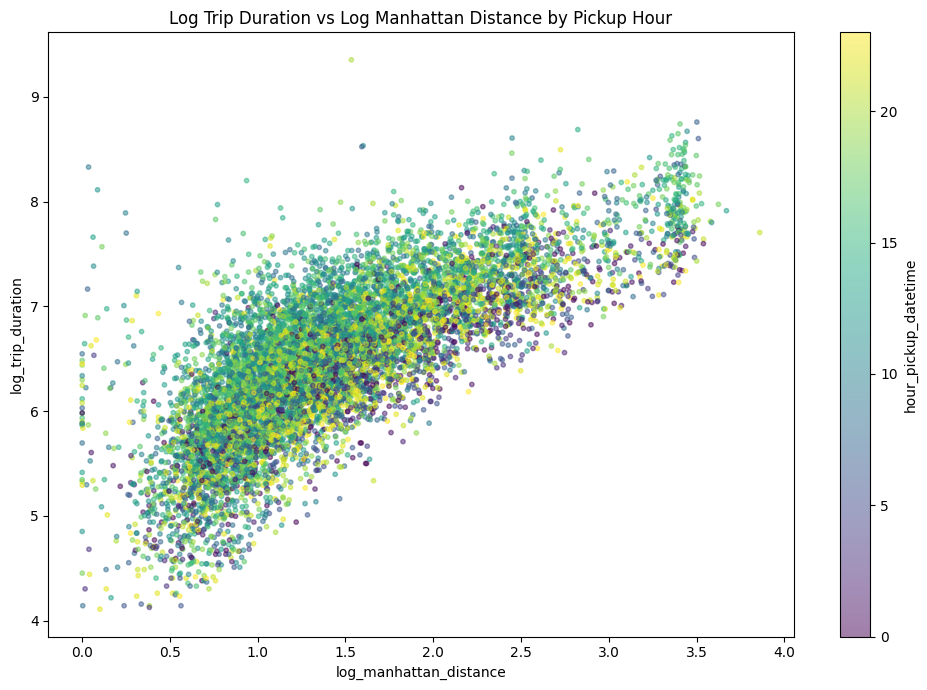

In [44]:
#scatter plot of log trip duration vs log manhattan distance, colored by pickup hour

df_plot_sample = df_train.sample(n=10000, random_state=42)

fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    df_plot_sample["log_manhattan_distance"],
    df_plot_sample["log_trip_duration"],
    c=df_plot_sample["hour_pickup_datetime"],
    cmap="viridis",
    alpha=0.5,
    s=10
)

ax.set_title("Log Trip Duration vs Log Manhattan Distance by Pickup Hour")
ax.set_xlabel("log_manhattan_distance")
ax.set_ylabel("log_trip_duration")

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("hour_pickup_datetime")

plt.tight_layout()
plt.show()


# 6. Correlation Analysis


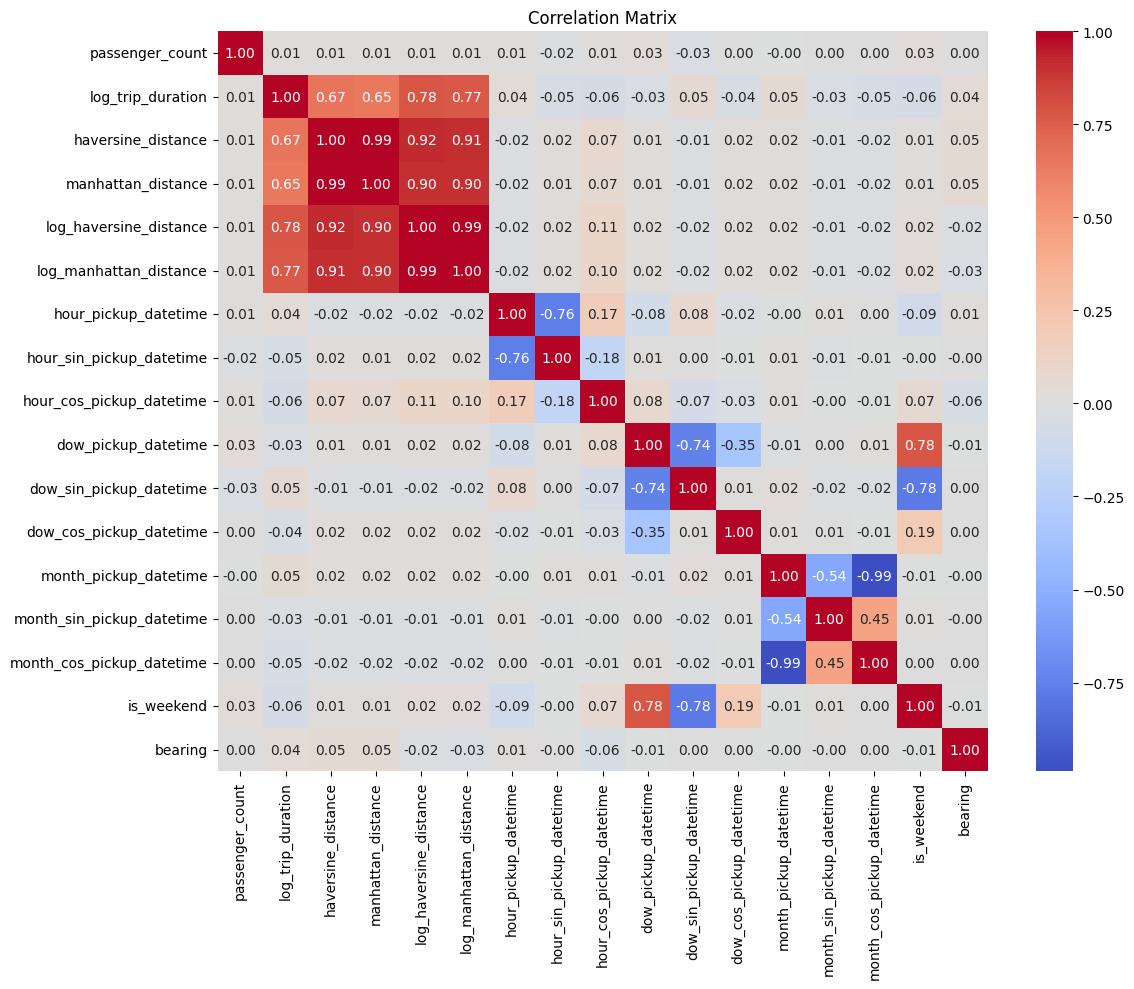

In [46]:
#correlation matrix

list_col_corr = [
    'passenger_count', 'log_trip_duration', 'haversine_distance',
    'manhattan_distance', 'log_haversine_distance',
    'log_manhattan_distance', 'hour_pickup_datetime',
    'hour_sin_pickup_datetime', 'hour_cos_pickup_datetime',
    'dow_pickup_datetime', 'dow_sin_pickup_datetime',
    'dow_cos_pickup_datetime', 'month_pickup_datetime',
    'month_sin_pickup_datetime', 'month_cos_pickup_datetime', 'is_weekend',
    'bearing'
]

corr_matrix = df_train[list_col_corr].corr()

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax
)

ax.set_title("Correlation Matrix")

plt.tight_layout()
plt.show()


In [47]:
df_train.columns

Index(['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime',
       'passenger_count', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag',
       'trip_duration', 'log_trip_duration', 'haversine_distance',
       'manhattan_distance', 'log_haversine_distance',
       'log_manhattan_distance', 'hour_pickup_datetime',
       'hour_sin_pickup_datetime', 'hour_cos_pickup_datetime',
       'dow_pickup_datetime', 'dow_sin_pickup_datetime',
       'dow_cos_pickup_datetime', 'month_pickup_datetime',
       'month_sin_pickup_datetime', 'month_cos_pickup_datetime', 'is_weekend',
       'bearing'],
      dtype='object')

# 7. Modeling

In [ ]:
features = ['pickup_datetime', 'dropoff_datetime',
       'passenger_count', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 
       'haversine_distance',
       'manhattan_distance', 'log_haversine_distance',
       'log_manhattan_distance', 'hour_pickup_datetime',
       'hour_sin_pickup_datetime', 'hour_cos_pickup_datetime',
       'dow_pickup_datetime', 'dow_sin_pickup_datetime',
       'dow_cos_pickup_datetime', 'month_pickup_datetime',
       'month_sin_pickup_datetime', 'month_cos_pickup_datetime', 'is_weekend',
       'bearing','bearing_sin','bearing_cos', 'store_and_fwd_flag_ind', 'vendor_id_1', 'vendor_id_2']

target = 'log_trip_duration'


X = df_train[features].copy()
y = df_train[target].copy()

X_test = df_test[features].copy()

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


In [ ]:
import mlflow


mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("NYC Taxi Trip Duration")